# Open-World Hierarchical Classification sur SIEVE
### Classification hiérarchique de logs SIEM en monde ouvert, avec estimation d'incertitude et rejet

**Projet 2** — *Open-World Hierarchical Cybersecurity Log Classification with Uncertainty-Aware Deep Learning*
Données : SIEVE (Artioli et al., *Computer Networks* 266, 2025) — 6 versions × 100 000 logs × 30 classes.

---
## Question de recherche
> Comment classer un événement dans une taxonomie de sécurité tout en reconnaissant qu'il ne correspond à **aucune** des classes apprises ?

## Plan du notebook
| # | Section | Contenu |
|---|---|---|
| 0 | Setup & logging | Config unique, logger → `recap.log`, seeds, GPU |
| 1 | Données | Chargement auto-détecté des 6 fichiers, contrôles qualité |
| 2 | Taxonomie | 30 classes → 9 familles (à faire valider par un expert SIEM) |
| 3 | Anti-fuite | Reconstruction des *templates* (groupes) + split **par template** |
| 4 | Versions bruitées | SIEVE_01…05 réservées au **test de robustesse** |
| 5 | Protocole open-set | **Rotations** des classes cachées (≥ 3, disjointes) |
| 6 | Modèle | Encodeur Transformer + tête famille + tête classe fine + loss de cohérence |
| 7 | Scores d'inconnu | MSP, Energy, Prototypes, MC-Dropout, score hiérarchique |
| 8 | Métriques | Macro-F1, AUROC, AUPR, FPR@95TPR, OSCR, ECE, F1 open-set… |
| 9 | E1 | Closed-set (30 classes connues) : flat vs hiérarchique |
| 10 | E2–E4 | Open-set × rotations × robustesse au bruit |
| 11 | Agrégation | Moyenne ± écart-type ± IC95 sur les rotations, tests appariés |
| 12 | Figures & `RECAP.md` | Tout est sauvegardé dans `outputs/` |

## Mapping avec les expériences du document de propositions
- **E1** closed-set → section 9
- **E2** open-set (masquage de 20 % des classes, plusieurs rotations) → section 10
- **E3** hiérarchie (famille puis classe fine) → métriques `fam_acc`, `tax_dist`, `unk_fam_acc`
- **E4** robustesse SIEVE_00…05 → section 10 (test sur les versions bruitées)
- **E5** transfert CDS → **impossible ici** : les 440 logs CDS originaux ne sont pas fournis. Les versions bruitées servent de proxy de robustesse, *pas* de transfert réel.

## Point méthodologique central (remarque du prof)
Un seul tirage de classes cachées peut être favorable/défavorable **par hasard**. On répète donc l'expérience sur **plusieurs ensembles de classes cachées disjoints** (par défaut 5 rotations de 6 classes = chaque classe est cachée exactement une fois) et on rapporte **moyenne ± écart-type ± IC95%**. L'écart-type entre rotations *est* la mesure de stabilité demandée.

# 0. Setup, configuration, logging
**Tout** ce que fait le notebook est écrit dans `outputs/recap.log` (fichier unique, chronologique) + tables CSV + figures. À la fin : `RECAP.md` (résumé propre) et un zip.

**Avant de lancer** : importer les 6 fichiers `output_*.log` dans `/content/data/` (ou mettre `USE_DRIVE=True`). Premier passage conseillé : `QUICK=True` (smoke test de ~5 min) puis `QUICK=False`.

In [1]:
# !pip -q install -U transformers      # décommenter si besoin (déjà présent sur Colab)
import os, sys, re, json, time, glob, math, copy, gc, random, pickle, platform, logging, zipfile
from pathlib import Path
from collections import OrderedDict
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             confusion_matrix, adjusted_rand_score)
from scipy import stats
import transformers
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

In [2]:
# ----------------------------- PARAMÈTRES À MODIFIER ICI -----------------------------
QUICK     = False      # True = smoke test rapide (peu de données, 1 epoch)
USE_DRIVE = False      # True = monte Google Drive (chemins à adapter ci-dessous)

CFG = dict(
    seed=42,
    backbone='distilbert-base-uncased',   # alternatives : 'bert-base-uncased', 'google/bert_uncased_L-4_H-256_A-4'
    max_len=96, batch_size=64, epochs=3, lr=5e-5, weight_decay=0.01, warmup_ratio=0.06,
    lambda_cons=0.5,                      # poids de la loss de cohérence hiérarchique
    n_rotations=5, n_unknown=6,           # >= 3 exigé par le prof ; 5x6 = les 30 classes cachées une fois chacune
    train_cap=1500, eval_cap=300, proto_cap=300,   # nb max de logs par classe (train / val-test / prototypes)
    split_frac=(0.6, 0.2, 0.2),           # train / val / test (au niveau des templates)
    strict_min_groups=5,                  # classe "stricte" = au moins 5 templates -> split par template possible
    tpr_target=0.95,                      # le seuil de rejet garde 95 % des connus (val)
    mc_passes=5, noise_levels=[0.1, 0.2, 0.3, 0.4, 0.5],
    fp16=True, resume=True,
)
if QUICK:
    CFG.update(epochs=1, n_rotations=3, train_cap=150, eval_cap=60, proto_cap=60, mc_passes=2, resume=False)
assert CFG['n_rotations'] >= 3, "Le prof exige au moins 3 variations de classes cachées"

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/OPEN-WORLD-SIEVE')
    DATA_DIR = BASE / 'data'
else:
    BASE = Path('/content')
    DATA_DIR = Path('/content/data')
OUT_DIR = BASE / ('outputs_quick' if QUICK else 'outputs')
for sub in ['', 'figs', 'ckpt', 'tables']:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

# ----------------------------- LOGGER -> outputs/recap.log -----------------------------
LOG_PATH = OUT_DIR / 'recap.log'
def init_logger():
    lg = logging.getLogger('ow'); lg.setLevel(logging.INFO); lg.handlers.clear()
    fmt = logging.Formatter('%(asctime)s | %(levelname)s | %(message)s', '%H:%M:%S')
    fh = logging.FileHandler(LOG_PATH, mode='a' if (CFG['resume'] and LOG_PATH.exists()) else 'w', encoding='utf-8')
    fh.setFormatter(fmt)
    sh = logging.StreamHandler(sys.stdout); sh.setFormatter(fmt)
    lg.addHandler(fh); lg.addHandler(sh); lg.propagate = False
    logging.captureWarnings(True)
    w = logging.getLogger('py.warnings'); w.handlers.clear(); w.addHandler(fh)
    return lg
log = init_logger()
def section(t): log.info('\n' + '=' * 100 + f'\n## {t}\n' + '=' * 100)
def log_df(title, df, **kw): log.info('\n--- %s ---\n%s', title, df.to_string(**kw))
def save_table(df, name, index=True): df.to_csv(OUT_DIR / 'tables' / f'{name}.csv', index=index)

# les exceptions de cellule sont aussi écrites dans le recap
try:
    _ip = get_ipython()
    def _exc(shell, etype, evalue, tb, tb_offset=None):
        log.error('EXCEPTION', exc_info=(etype, evalue, tb))
        shell.showtraceback((etype, evalue, tb), tb_offset=tb_offset)
    _ip.set_custom_exc((Exception,), _exc)
except NameError:
    pass

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = bool(CFG['fp16'] and DEVICE.type == 'cuda')
set_seed(CFG['seed'])

section('ENVIRONNEMENT & CONFIGURATION')
log.info('python=%s | torch=%s | transformers=%s | device=%s | gpu=%s | AMP=%s', platform.python_version(),
         torch.__version__, transformers.__version__, DEVICE,
         torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'none', AMP)
log.info('QUICK=%s | DATA_DIR=%s | OUT_DIR=%s', QUICK, DATA_DIR, OUT_DIR)
log.info('CFG=%s', json.dumps(CFG, indent=1))
json.dump(CFG, open(OUT_DIR / 'config.json', 'w'), indent=1)
if DEVICE.type == 'cpu':
    log.warning('Pas de GPU détecté. Colab : Exécution > Modifier le type d\'exécution > GPU (T4).')

08:42:27 | INFO | 
## ENVIRONNEMENT & CONFIGURATION
08:42:27 | INFO | python=3.13.16 | torch=2.14.1+cu130 | transformers=5.22.1 | device=cuda | gpu=Tesla T4 | AMP=True
08:42:27 | INFO | QUICK=False | DATA_DIR=/content/data | OUT_DIR=/content/outputs
08:42:27 | INFO | CFG={
 "seed": 42,
 "backbone": "distilbert-base-uncased",
 "max_len": 96,
 "batch_size": 64,
 "epochs": 3,
 "lr": 5e-05,
 "weight_decay": 0.01,
 "warmup_ratio": 0.06,
 "lambda_cons": 0.5,
 "n_rotations": 5,
 "n_unknown": 6,
 "train_cap": 1500,
 "eval_cap": 300,
 "proto_cap": 300,
 "split_frac": [
  0.6,
  0.2,
  0.2
 ],
 "strict_min_groups": 5,
 "tpr_target": 0.95,
 "mc_passes": 5,
 "noise_levels": [
  0.1,
  0.2,
  0.3,
  0.4,
  0.5
 ],
 "fp16": true,
 "resume": true
}


# 1. Chargement des données
Les 6 fichiers : `output_0.log` (= **SIEVE_00**, $p=0$, base d'entraînement) et `output_0.1.log` … `output_0.5.log` (versions bruitées, **uniquement pour le test de robustesse**).

Le format exact du `.log` n'est pas garanti → le loader **auto-détecte** : CSV avec en-tête, JSON lines, ou lignes `label<sep>texte` / `texte<sep>label` (séparateurs `, ; \t |`). Si rien ne marche, il affiche les premières lignes brutes pour qu'on adapte.

**Contrôles qualité** : doublons exacts, conflits de labels (même texte, 2 classes), distribution par classe, longueur, ordre du fichier.

In [3]:
section('1. CHARGEMENT DES DONNÉES')
CLASS_NAMES = ['authentication-failed','authentication-success','connection-closed','connection-failed','connection-opened',
 'database-operation','directory-changed','directory-created','directory-deleted','file-action-failure','file-deleted',
 'file-modification','file-read','file-write','hardware-monitoring','http-request-failure','http-request-success','ids-alert',
 'network-filtered','network-traffic','process-ended','process-error','process-info','process-shutdown','process-started',
 'system-configuration-changed','user-creation','user-deletion','user-logout','user-session-open']
# nb de templates (logs CDS originaux) par classe — Table 1 de l'article (somme = 440)
CDS_COUNT = [69,37,15,13,16,9,4,3,3,2,4,2,3,3,22,3,4,93,7,6,6,6,7,12,34,22,8,5,19,3]
assert len(CLASS_NAMES) == 30 and sum(CDS_COUNT) == 440
NAME2ID = {n: i for i, n in enumerate(CLASS_NAMES)}

def _parse_label(tok):
    t = str(tok).strip().strip('"\'').strip()
    if t in NAME2ID: return NAME2ID[t]
    try:
        v = float(t)
        if v == int(v) and 0 <= int(v) < 30: return int(v)
    except ValueError: pass
    return None

def _cols(df):
    cols = {str(c).lower().strip(): c for c in df.columns}
    lab = next((cols[k] for k in ['label', 'class', 'category', 'type', 'classe', 'target', 'y'] if k in cols), None)
    txt = next((cols[k] for k in ['log', 'text', 'message', 'raw', 'content', 'logs', 'event', 'sentence', 'x'] if k in cols), None)
    return lab, txt

def read_sieve_file(path):
    # 1) CSV avec en-tête
    try:
        df = pd.read_csv(path)
        lab, txt = _cols(df)
        if lab is not None and txt is not None:
            return df[[txt, lab]].rename(columns={txt: 'text', lab: 'label_raw'}), 'csv-header'
    except Exception: pass
    # 2) JSON lines
    try:
        df = pd.read_json(path, lines=True)
        lab, txt = _cols(df)
        if lab is not None and txt is not None:
            return df[[txt, lab]].rename(columns={txt: 'text', lab: 'label_raw'}), 'jsonl'
    except Exception: pass
    # 3) heuristique ligne par ligne : "label<d>texte" ou "texte<d>label"
    lines = [l for l in Path(path).read_text(encoding='utf-8', errors='replace').splitlines() if l.strip()]
    sample = lines[:500]; best = (0, None, None)
    for d in [',', '\t', ';', '|']:
        for side in ['first', 'last']:
            ok = 0
            for l in sample:
                parts = l.split(d, 1) if side == 'first' else l.rsplit(d, 1)
                if len(parts) == 2 and _parse_label(parts[0 if side == 'first' else 1]) is not None: ok += 1
            if ok / max(1, len(sample)) > best[0]: best = (ok / max(1, len(sample)), d, side)
    if best[0] > 0.9:
        _, d, side = best; rows = []
        for l in lines:
            parts = l.split(d, 1) if side == 'first' else l.rsplit(d, 1)
            if len(parts) != 2: continue
            lab, txt = (parts[0], parts[1]) if side == 'first' else (parts[1], parts[0])
            rows.append((txt.strip().strip('"'), lab))
        return pd.DataFrame(rows, columns=['text', 'label_raw']), f'lines(delim={d!r},label={side})'
    raise ValueError(f'Format non reconnu pour {path}. Premières lignes :\n' + '\n'.join(l[:200] for l in lines[:5]))

def discover_files():
    cands = sorted(DATA_DIR.glob('*.log')) if DATA_DIR.exists() else []
    if not cands: cands = sorted(Path('/content').rglob('output_*.log'))
    files = {}
    for f in cands:
        m = re.match(r'^output_(\d+(?:\.\d+)?)\.log$', f.name)
        if m: files[round(float(m.group(1)), 2)] = f
    return files

FILES = discover_files()
log.info('Fichiers trouvés : %s', {k: str(v) for k, v in FILES.items()})
need = [0.0] + CFG['noise_levels']
missing = [p for p in need if p not in FILES]
assert not missing, f'Fichiers manquants pour p={missing}. Vérifier DATA_DIR={DATA_DIR}'

DATA, QC = {}, []
for p in need:
    f = FILES[p]
    raw_head = [l[:160] for l in f.open(encoding='utf-8', errors='replace').readlines()[:3]]
    log.info('[p=%s] %s | aperçu brut : %s', p, f.name, raw_head)
    df, how = read_sieve_file(f)
    n0 = len(df)
    df['label'] = df['label_raw'].map(_parse_label)
    bad = int(df['label'].isna().sum()); df = df.dropna(subset=['label']).copy()
    df['label'] = df['label'].astype(int); df['text'] = df['text'].astype(str).str.strip()
    n_dup = int(df.duplicated('text').sum())
    conflicts = df.groupby('text')['label'].nunique(); conflicts = conflicts[conflicts > 1].index
    n_conf = int(df['text'].isin(conflicts).sum())
    df = df[~df['text'].isin(conflicts)].drop_duplicates('text').reset_index(drop=True)
    runs = int((df['label'].values[1:] != df['label'].values[:-1]).sum() + 1)
    DATA[p] = df
    cc = df['label'].value_counts()
    QC.append(dict(p=p, format=how, rows_raw=n0, bad_label=bad, exact_dups_removed=n_dup, conflict_rows_removed=n_conf,
                   rows_kept=len(df), n_classes=df['label'].nunique(), min_per_class=int(cc.min()), max_per_class=int(cc.max()),
                   label_runs=runs, mean_chars=round(df['text'].str.len().mean(), 1)))
QC = pd.DataFrame(QC).set_index('p')
log_df('Contrôle qualité des fichiers', QC); save_table(QC, 'qc_files')
if (QC['n_classes'] != 30).any(): log.warning('Une version n\'a pas 30 classes !')
if QC.loc[0.0, 'label_runs'] <= 31: log.info('Le fichier SIEVE_00 est ORDONNÉ par classe (%d blocs).', QC.loc[0.0, 'label_runs'])
FILE_ORDERED = bool(QC.loc[0.0, 'label_runs'] <= 31)
D0 = DATA[0.0].copy()
ov = {p: len(set(D0.text) & set(DATA[p].text)) for p in CFG['noise_levels']}
log.info('Textes identiques entre SIEVE_00 et chaque version bruitée (doublons inter-versions) : %s', ov)
log_df('Exemples SIEVE_00', D0.sample(6, random_state=0).assign(classe=lambda d: d.label.map(lambda i: CLASS_NAMES[i]))[['text', 'classe']], max_colwidth=140)

08:42:27 | INFO | 
## 1. CHARGEMENT DES DONNÉES
08:42:27 | INFO | Fichiers trouvés : {0.1: '/content/data/output_0.1.log', 0.2: '/content/data/output_0.2.log', 0.3: '/content/data/output_0.3.log', 0.4: '/content/data/output_0.4.log', 0.5: '/content/data/output_0.5.log', 0.0: '/content/data/output_0.log'}
08:42:27 | INFO | [p=0.0] output_0.log | aperçu brut : ['category,log\n', 'authentication-failed,[Wed Nov 03 19:30:11 1976] [error] [client 217.121.56.73] user clarkesummer: authentication failure for "/at/challenge.png/pass": Password', 'authentication-failed,[Sat May 21 08:27:17 1988] [error] [client 195.255.99.164] user alicekelly: authentication failure for "/age/evidence.mp3/be": Password Mi']
08:42:27 | INFO | [p=0.1] output_0.1.log | aperçu brut : ['category,log\n', 'authentication-failed,[Tue Apr 11 14:36:11 2000] [error] [client 28.213.68.3] user jessicakaiser: authentication failure for "/here/once.odp/lose": Password Mis', 'authentication-failed,[Tue Jan 21 17:01:07 2020] [e

# 2. Taxonomie hiérarchique (30 classes → 9 familles)
SIEVE fournit 30 labels **à plat** (sémantique de type `event.action` de l'ECS). **La hiérarchie n'est pas fournie** : c'est une construction scientifique de notre part, regroupée par *fonction* de l'événement :

| Famille | Classes enfants |
|---|---|
| authentication | authentication-failed, authentication-success |
| connection | connection-closed / -failed / -opened |
| directory | directory-changed / -created / -deleted |
| file | file-action-failure, file-deleted, file-modification, file-read, file-write |
| http | http-request-failure / -success |
| network_security | ids-alert, network-filtered, network-traffic |
| process | process-ended / -error / -info / -shutdown / -started |
| system | database-operation, hardware-monitoring, system-configuration-changed |
| user | user-creation, user-deletion, user-logout, user-session-open |

**Cas ambigus documentés** : `user-logout`↔`connection-closed` (confondus par les modèles de l'article), `directory-*`↔`file-*` (fusion possible), `authentication-failed`↔`-success` (même famille, critique SIEM), `ids-alert` vs `network-*`.
> À faire valider par un spécialiste SIEM avant soumission. Le dictionnaire `TAXONOMY` ci-dessous est la **seule** chose à modifier pour tester une autre hiérarchie.

**Distance taxonomique** entre classe vraie et prédite : 0 (identique), 1 (même famille), 2 (familles différentes).

In [4]:
section('2. TAXONOMIE')
TAXONOMY = OrderedDict([
    ('authentication',   ['authentication-failed', 'authentication-success']),
    ('connection',       ['connection-closed', 'connection-failed', 'connection-opened']),
    ('directory',        ['directory-changed', 'directory-created', 'directory-deleted']),
    ('file',             ['file-action-failure', 'file-deleted', 'file-modification', 'file-read', 'file-write']),
    ('http',             ['http-request-failure', 'http-request-success']),
    ('network_security', ['ids-alert', 'network-filtered', 'network-traffic']),
    ('process',          ['process-ended', 'process-error', 'process-info', 'process-shutdown', 'process-started']),
    ('system',           ['database-operation', 'hardware-monitoring', 'system-configuration-changed']),
    ('user',             ['user-creation', 'user-deletion', 'user-logout', 'user-session-open']),
])
FAM_NAMES = list(TAXONOMY.keys()); N_FAM = len(FAM_NAMES)
allc = [c for v in TAXONOMY.values() for c in v]
assert sorted(allc) == sorted(CLASS_NAMES) and len(set(allc)) == 30, 'La taxonomie doit couvrir exactement les 30 classes'
CLASS2FAM = np.zeros(30, dtype=int)
for fi, (f, cl) in enumerate(TAXONOMY.items()):
    for c in cl: CLASS2FAM[NAME2ID[c]] = fi
FAM_CLASSES = [[NAME2ID[c] for c in cl] for cl in TAXONOMY.values()]
log.info('Taxonomie : %d familles', N_FAM)
for f, cl in TAXONOMY.items(): log.info('  %-17s (%d) : %s', f, len(cl), ', '.join(cl))
D0['fam'] = CLASS2FAM[D0.label.values]

08:42:29 | INFO | 
## 2. TAXONOMIE
08:42:29 | INFO | Taxonomie : 9 familles
08:42:29 | INFO |   authentication    (2) : authentication-failed, authentication-success
08:42:29 | INFO |   connection        (3) : connection-closed, connection-failed, connection-opened
08:42:29 | INFO |   directory         (3) : directory-changed, directory-created, directory-deleted
08:42:29 | INFO |   file              (5) : file-action-failure, file-deleted, file-modification, file-read, file-write
08:42:29 | INFO |   http              (2) : http-request-failure, http-request-success
08:42:29 | INFO |   network_security  (3) : ids-alert, network-filtered, network-traffic
08:42:29 | INFO |   process           (5) : process-ended, process-error, process-info, process-shutdown, process-started
08:42:29 | INFO |   system            (3) : database-operation, hardware-monitoring, system-configuration-changed
08:42:29 | INFO |   user              (4) : user-creation, user-deletion, user-logout, user-session-op

# 3. Anti-fuite : reconstruction des templates et split par template
## Le problème
SIEVE_00 = **440 templates** (logs réels masqués) × ~227 instanciations Faker (IP, user, host… aléatoires). Un split aléatoire met donc des variantes quasi identiques du même template en train **et** en test → performances artificiellement gonflées (le papier le signale : « éviter qu'une variante presque identique soit présente en train et en test »). Pire en open-set : un modèle qui a mémorisé les templates paraît « calibré » sur le connu.

## Solution
1. **Reconstruire les groupes** = templates. On connaît le **nombre exact de templates par classe** (Table 1 : `CDS_COUNT`). Pour chaque classe on fait un **KMeans (k = nb de templates)** sur du TF-IDF de mots alphabétiques (les chiffres/IP/ports disparaissent ; `min_df` ≈ 30 % de la taille attendue d'un template élimine les mots aléatoires Faker et ne garde que le squelette fixe du template).
2. **Split au niveau des groupes** (60/20/20) : aucun template du test/val n'apparaît dans le train.
3. **Limite honnête** : 12 classes ont < 5 templates (ex. `file-modification` : 2). Un split par template y est impossible (il ne resterait rien pour apprendre). Pour ces classes **« non strictes »** on fait un split aléatoire **avec fuite résiduelle**. Toutes les métriques sont donc rapportées en **deux vues** :
   - `all` : toutes les classes connues ;
   - `strict` : uniquement les classes connues à split par template (sans fuite) → **la vue la plus fiable**.

In [5]:
section('3. GROUPES (TEMPLATES) ET SPLIT')
GROUP_INFO = {}
def build_groups(D0):
    g = np.zeros(len(D0), dtype=int); off = 0; recs = []
    for c in range(30):
        idx = np.where(D0.label.values == c)[0]; k = CDS_COUNT[c]; texts = D0.text.values[idx]
        exp = len(idx) / k
        X = None
        for mdf in [max(3, int(0.3 * exp)), 3, 2]:
            try:
                vec = TfidfVectorizer(token_pattern=r'[a-z]{2,}', lowercase=True, min_df=mdf, sublinear_tf=True)
                X = vec.fit_transform(texts); break
            except ValueError: continue
        kk = min(k, len(idx))
        km = KMeans(n_clusters=kk, n_init=5, random_state=CFG['seed']).fit(X)
        cent = km.cluster_centers_.copy(); cent /= (np.linalg.norm(cent, axis=1, keepdims=True) + 1e-12)
        g[idx] = off + km.labels_
        GROUP_INFO[c] = dict(vec=vec, cent=cent, offset=off, k=kk)
        sizes = np.bincount(km.labels_, minlength=kk)
        r = dict(cls=CLASS_NAMES[c], templates_expected=k, groups=int((sizes > 0).sum()), expected_size=round(exp, 1),
                 size_min=int(sizes.min()), size_max=int(sizes.max()), size_cv=round(float(sizes.std() / sizes.mean()), 2),
                 empty_vec_rate=round(float((X.getnnz(axis=1) == 0).mean()), 3), vocab=len(vec.vocabulary_))
        if FILE_ORDERED:   # diagnostic : le fichier est généré template par template -> blocs consécutifs
            blocks = (np.arange(len(idx)) * kk // len(idx))
            r['ARI_vs_blocks'] = round(float(adjusted_rand_score(blocks, km.labels_)), 3)
        recs.append(r); off += kk
    return g, pd.DataFrame(recs).set_index('cls')

t0 = time.time()
D0['group'], GRP = build_groups(D0)
log_df('Qualité de la reconstruction des templates (size_cv bas = groupes homogènes comme attendu)', GRP)
save_table(GRP, 'groups_quality')
log.info('Groupes construits en %.1fs | total groupes = %d', time.time() - t0, D0.group.nunique())
if FILE_ORDERED: log.info('ARI moyen vs blocs du fichier = %.3f (≈1 : les groupes coïncident avec les templates réels)', GRP['ARI_vs_blocks'].mean())

def assign_groups(df):
    # affecte chaque log (donc aussi les logs bruités) au centroïde le plus proche DANS SA CLASSE
    gid = np.full(len(df), -1); sim = np.zeros(len(df))
    for c in range(30):
        idx = np.where(df.label.values == c)[0]
        if len(idx) == 0: continue
        gi = GROUP_INFO[c]; X = gi['vec'].transform(df.text.values[idx])
        S = np.asarray(X @ gi['cent'].T)
        gid[idx] = gi['offset'] + S.argmax(1); sim[idx] = S.max(1)
    return gid, sim

_g, _s = assign_groups(D0)
log.info('Cohérence assign_groups vs KMeans sur SIEVE_00 : %.4f', float((_g == D0.group.values).mean()))

def make_split(D0):
    rng = np.random.RandomState(CFG['seed']); split = np.array(['train'] * len(D0), dtype=object)
    strict = np.zeros(30, bool); test_groups = set()
    fv, ft = CFG['split_frac'][1], CFG['split_frac'][2]
    for c in range(30):
        idx = np.where(D0.label.values == c)[0]; gs = np.unique(D0.group.values[idx])
        if len(gs) >= CFG['strict_min_groups']:
            strict[c] = True; perm = rng.permutation(gs)
            nt = max(1, int(round(ft * len(gs)))); nv = max(1, int(round(fv * len(gs))))
            tg, vg = perm[:nt], perm[nt:nt + nv]
            split[idx[np.isin(D0.group.values[idx], tg)]] = 'test'
            split[idx[np.isin(D0.group.values[idx], vg)]] = 'val'
            test_groups.update(tg.tolist())
        else:   # split aléatoire (fuite résiduelle) pour les classes à très peu de templates
            perm = rng.permutation(idx); nt = int(round(ft * len(idx))); nv = int(round(fv * len(idx)))
            split[perm[:nt]] = 'test'; split[perm[nt:nt + nv]] = 'val'
    return split, strict, np.array(sorted(test_groups))

D0['split'], STRICT, TEST_GROUPS = make_split(D0)
D0['strict'] = STRICT[D0.label.values]
tab = D0.groupby('label').agg(n=('text', 'size'), groups=('group', 'nunique'), strict=('strict', 'first'),
                              train=('split', lambda s: (s == 'train').sum()), val=('split', lambda s: (s == 'val').sum()),
                              test=('split', lambda s: (s == 'test').sum()))
tab.index = [CLASS_NAMES[i] for i in tab.index]
log_df('Split par classe', tab); save_table(tab, 'split_per_class')
log.info('Classes STRICTES (split par template, sans fuite) : %d/30 | NON strictes (fuite résiduelle) : %s',
         STRICT.sum(), [CLASS_NAMES[c] for c in range(30) if not STRICT[c]])
# vérification d'absence de fuite : aucun groupe ne doit être à la fois dans train et test pour les classes strictes
chk = D0[D0.strict].groupby('group')['split'].nunique()
log.info('Fuite de template (classes strictes) : %d groupes présents dans >1 split (attendu 0)', int((chk > 1).sum()))
assert int((chk > 1).sum()) == 0

08:42:29 | INFO | 
## 3. GROUPES (TEMPLATES) ET SPLIT
08:42:31 | INFO | 
--- Qualité de la reconstruction des templates (size_cv bas = groupes homogènes comme attendu) ---
                              templates_expected  groups  expected_size  size_min  size_max  size_cv  empty_vec_rate  vocab  ARI_vs_blocks
cls                                                                                                                                       
authentication-failed                         69      69           16.9         2        34     0.35             0.0    232          0.669
authentication-success                        37      37           31.5         5        62     0.49             0.0    128          0.540
connection-closed                             15      15           77.5        21       155     0.32             0.0    120          0.892
connection-failed                             13      13           89.8        88        91     0.01             0.0    103          

# 4. Versions bruitées (SIEVE_01 … 05) = test de robustesse uniquement
Le modèle **n'est entraîné que sur SIEVE_00** ($p=0$). Les versions $p\in\{0.1,\dots,0.5\}$ ne servent qu'à tester.
Pour ne pas retomber dans la fuite de templates : chaque log bruité est rattaché au **template le plus proche de sa classe** (centroïde), et on ne garde que ceux rattachés à un **template de test**. Pour les classes non strictes : un échantillon aléatoire de 20 %.
Le rattachement n'est qu'approximatif quand $p$ est grand → on logue la similarité moyenne.

In [6]:
section('4. VERSIONS BRUITÉES')
NOISY = {}; rows = []
for p in CFG['noise_levels']:
    Dp = DATA[p].copy()
    gid, sim = assign_groups(Dp); Dp['group'] = gid; Dp['sim'] = sim
    keep = np.zeros(len(Dp), bool); rs = np.random.RandomState(CFG['seed'] + int(p * 100))
    for c in range(30):
        idx = np.where(Dp.label.values == c)[0]
        if STRICT[c]: keep[idx] = np.isin(gid[idx], TEST_GROUPS)
        else:         keep[idx] = rs.rand(len(idx)) < CFG['split_frac'][2]
    Dp['strict'] = STRICT[Dp.label.values]
    NOISY[p] = Dp[keep].reset_index(drop=True)
    rows.append(dict(p=p, rows=len(Dp), kept_for_test=int(keep.sum()), mean_sim=round(float(sim.mean()), 3),
                     zero_sim_rate=round(float((sim == 0).mean()), 4)))
R4 = pd.DataFrame(rows).set_index('p'); log_df('Versions bruitées : rattachement aux templates', R4); save_table(R4, 'noisy_assignment')

def cap_per_class(df, cap, seed):
    df = df.sample(frac=1, random_state=seed)
    return df[df.groupby('label').cumcount() < cap].reset_index(drop=True)
TR_DF = cap_per_class(D0[D0.split == 'train'], CFG['train_cap'], CFG['seed'])
VA_DF = cap_per_class(D0[D0.split == 'val'],   CFG['eval_cap'],  CFG['seed'])
TE_DF = cap_per_class(D0[D0.split == 'test'],  CFG['eval_cap'],  CFG['seed'])
NZ_DF = {p: cap_per_class(NOISY[p], CFG['eval_cap'], CFG['seed']) for p in CFG['noise_levels']}
PR_DF = cap_per_class(TR_DF, CFG['proto_cap'], CFG['seed'])
log.info('Tailles après plafonnement par classe : train=%d val=%d test=%d proto=%d noisy=%s', len(TR_DF), len(VA_DF), len(TE_DF), len(PR_DF),
         {p: len(v) for p, v in NZ_DF.items()})

08:42:32 | INFO | 
## 4. VERSIONS BRUITÉES
08:42:34 | INFO | 
--- Versions bruitées : rattachement aux templates ---
      rows  kept_for_test  mean_sim  zero_sim_rate
p                                                 
0.1  35000           6996     0.895         0.0008
0.2  35000           6927     0.867         0.0013
0.3  35000           6943     0.847         0.0021
0.4  35000           6858     0.830         0.0023
0.5  35000           6956     0.808         0.0025
08:42:34 | INFO | Tailles après plafonnement par classe : train=21185 val=6845 test=6882 proto=9000 noisy={0.1: 6914, 0.2: 6879, 0.3: 6877, 0.4: 6804, 0.5: 6880}


# 5. Protocole open-set avec rotations des classes cachées
Soit $\mathcal C=\{1..30\}$ l'ensemble des classes. À chaque rotation $r$ :
- $\mathcal U_r\subset\mathcal C$, $|\mathcal U_r|=6$ (20 %) : classes **inconnues**, jamais vues à l'entraînement, ni en validation ;
- $\mathcal K_r=\mathcal C\setminus\mathcal U_r$ : classes **connues**.

**Contraintes** :
1. les $\mathcal U_r$ sont **disjoints** (si $R\times 6\le 30$) → chaque classe est cachée exactement une fois, aucun biais de sélection ;
2. chaque **famille garde au moins une classe connue** → la tête « famille » est toujours entraînée sur toutes les familles, ce qui permet d'évaluer si un inconnu est rattaché à la **bonne famille** (la valeur ajoutée d'une approche hiérarchique).

Seuil de rejet : calibré **uniquement** sur la validation de classes connues (aucune classe inconnue n'est utilisée pour régler quoi que ce soit).

In [7]:
section('5. ROTATIONS DES CLASSES CACHÉES')
def make_rotations(n_rot, n_unk, seed):
    rng = np.random.RandomState(seed)
    def valid(u):
        kn = set(range(30)) - set(u)
        return all(any(c in kn for c in cl) for cl in FAM_CLASSES)
    if n_rot * n_unk <= 30:
        for _ in range(20000):
            perm = rng.permutation(30); ch = [sorted(perm[i * n_unk:(i + 1) * n_unk].tolist()) for i in range(n_rot)]
            if all(valid(u) for u in ch): return ch
        raise RuntimeError('Impossible de trouver des rotations valides')
    sets = []
    while len(sets) < n_rot:
        u = sorted(rng.choice(30, n_unk, replace=False).tolist())
        if valid(u) and u not in sets: sets.append(u)
    return sets

ROTATIONS = make_rotations(CFG['n_rotations'], CFG['n_unknown'], CFG['seed'])
rt = pd.DataFrame([dict(rotation=i, unknown=[CLASS_NAMES[c] for c in u],
                        unknown_families=sorted({FAM_NAMES[CLASS2FAM[c]] for c in u}),
                        n_unknown_strict=int(STRICT[u].sum())) for i, u in enumerate(ROTATIONS)]).set_index('rotation')
log_df('Rotations (classes cachées)', rt, max_colwidth=200); save_table(rt, 'rotations')
allu = [c for u in ROTATIONS for c in u]
log.info('Rotations disjointes : %s | classes couvertes comme inconnues : %d/30', len(allu) == len(set(allu)), len(set(allu)))

08:42:34 | INFO | 
## 5. ROTATIONS DES CLASSES CACHÉES
08:42:34 | INFO | 
--- Rotations (classes cachées) ---
                                                                                                                       unknown                                          unknown_families  n_unknown_strict
rotation                                                                                                                                                                                                  
0                   [directory-deleted, file-action-failure, http-request-failure, ids-alert, process-shutdown, user-deletion]  [directory, file, http, network_security, process, user]                 3
1                    [authentication-failed, connection-opened, file-read, http-request-success, process-started, user-logout]   [authentication, connection, file, http, process, user]                 4
2                 [authentication-success, connection-closed, database-operati

# 6. Modèle hiérarchique
## Architecture
Un encodeur Transformer partagé (DistilBERT par défaut) → embedding $h(x)\in\mathbb R^d$ (moyenne des tokens) → deux têtes linéaires :
- **tête famille** $q(x)=\mathrm{softmax}(W_F h)\in\Delta^{9}$ ;
- **tête classe fine** $p(x)=\mathrm{softmax}(W_K h)\in\Delta^{|\mathcal K|}$ (uniquement les classes **connues**).

Soit $\phi(k)$ la famille de la classe $k$.

## Loss
$$\mathcal L=\underbrace{\mathrm{CE}(p,y)}_{\text{classe fine}}+\underbrace{\mathrm{CE}(q,\phi(y))}_{\text{famille}}+\lambda\,\underbrace{\Big(-\log\sum_{k\in\mathcal K}p_k\,q_{\phi(k)}\Big)}_{\text{cohérence hiérarchique}}$$
Le dernier terme est $-\log$ de la **probabilité que les deux têtes s'accordent** : il pénalise une classe fine prédite hors de la famille prédite. À l'inférence, le décodage **contraint** choisit $\hat f=\arg\max q$ puis $\hat k=\arg\max_{k:\phi(k)=\hat f}p_k$ (cohérence garantie).

## Baseline *flat*
Même encodeur, **sans** tête famille ni cohérence (CE seule). Mêmes données, même seed → seule la hiérarchie diffère.

In [8]:
section('6. MODÈLE')
TOK = AutoTokenizer.from_pretrained(CFG['backbone'])

class TokData:
    def __init__(self, df):
        self.ids = TOK(list(df.text), truncation=True, max_length=CFG['max_len'])['input_ids']
        self.y = df.label.values.astype(int); self.strict = df.strict.values.astype(bool)
    def sub(self, mask):
        o = copy.copy(self); mask = np.asarray(mask, bool)
        o.ids = [x for x, m in zip(self.ids, mask) if m]; o.y = self.y[mask]; o.strict = self.strict[mask]; return o

t0 = time.time()
TR, VA, TE, PR = TokData(TR_DF), TokData(VA_DF), TokData(TE_DF), TokData(PR_DF)
NZ = {p: TokData(NZ_DF[p]) for p in CFG['noise_levels']}
lens = np.array([len(x) for x in TR.ids])
log.info('Tokenisation en %.1fs | longueur tokens train : moy=%.1f p95=%d max=%d | tronqués (>=%d) : %.2f%%', time.time() - t0,
         lens.mean(), np.percentile(lens, 95), lens.max(), CFG['max_len'], 100 * (lens >= CFG['max_len']).mean())

class DS(Dataset):
    def __init__(self, td, kmap):
        self.ids = td.ids; self.yl = np.array([kmap.get(int(c), -1) for c in td.y]); self.yf = CLASS2FAM[td.y]
    def __len__(self): return len(self.ids)
    def __getitem__(self, i): return self.ids[i], int(self.yl[i]), int(self.yf[i])

def collate(batch):
    L = max(len(b[0]) for b in batch)
    ids = torch.full((len(batch), L), TOK.pad_token_id, dtype=torch.long); mask = torch.zeros(len(batch), L, dtype=torch.long)
    for i, (x, _, _) in enumerate(batch):
        ids[i, :len(x)] = torch.tensor(x); mask[i, :len(x)] = 1
    return ids, mask, torch.tensor([b[1] for b in batch]), torch.tensor([b[2] for b in batch])

class HierModel(nn.Module):
    def __init__(self, n_fine, n_fam, use_family):
        super().__init__()
        self.enc = AutoModel.from_pretrained(CFG['backbone'])
        h = self.enc.config.hidden_size
        self.drop = nn.Dropout(0.1); self.fine = nn.Linear(h, n_fine)
        self.fam = nn.Linear(h, n_fam) if use_family else None
    def forward(self, ids, mask):
        hs = self.enc(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).to(hs.dtype)
        z = (hs * m).sum(1) / m.sum(1).clamp_min(1)          # mean pooling
        zd = self.drop(z)
        return self.fine(zd), (self.fam(zd) if self.fam is not None else None), z

def hier_loss(lf, lfam, yl, yf, M, lam):
    ce = F.cross_entropy(lf, yl)
    if lfam is None: return ce, dict(ce_fine=ce.item())
    cf = F.cross_entropy(lfam, yf)
    p, q = F.softmax(lf, 1), F.softmax(lfam, 1)
    agree = (p * (q @ M.T)).sum(1)                           # sum_k p_k q_phi(k)
    cons = -torch.log(agree.clamp_min(1e-8)).mean()
    return ce + cf + lam * cons, dict(ce_fine=ce.item(), ce_fam=cf.item(), cons=cons.item())

def make_M(known):
    M = torch.zeros(len(known), N_FAM)
    for i, c in enumerate(known): M[i, CLASS2FAM[c]] = 1
    return M

@torch.no_grad()
def infer(model, ds, mc=0, bs=256):
    dl = DataLoader(ds, batch_size=bs, shuffle=False, collate_fn=collate)
    dtype_dev = 'cuda' if DEVICE.type == 'cuda' else 'cpu'
    model.eval(); LF, LFAM, EMB = [], [], []
    for ids, mask, _, _ in dl:
        with torch.autocast(dtype_dev, dtype=torch.float16, enabled=AMP):
            lf, lfam, z = model(ids.to(DEVICE), mask.to(DEVICE))
        LF.append(lf.float().cpu()); EMB.append(z.float().cpu())
        if lfam is not None: LFAM.append(lfam.float().cpu())
    out = dict(lf=torch.cat(LF), emb=torch.cat(EMB), lfam=torch.cat(LFAM) if LFAM else None)
    if mc > 0:                                              # MC-Dropout : dropout actif à l'inférence
        model.train(); P = 0
        for _ in range(mc):
            pr = []
            for ids, mask, _, _ in dl:
                with torch.autocast(dtype_dev, dtype=torch.float16, enabled=AMP):
                    lf, _, _ = model(ids.to(DEVICE), mask.to(DEVICE))
                pr.append(F.softmax(lf.float(), 1).cpu())
            P = P + torch.cat(pr)
        out['mc_probs'] = P / mc; model.eval()
    return out

def decode(out, M, use_family):
    """Retourne (pred locale, famille prédite, taux de cohérence brut classe/famille avant contrainte)."""
    lf = out['lf']; fam_loc = M.argmax(1)
    raw = lf.argmax(1)
    if use_family:
        fam = out['lfam'].argmax(1)
        mask = M[:, fam].T.bool()
        pred = lf.masked_fill(~mask, -1e9).argmax(1)
        cons = (fam_loc[raw] == fam).float().mean().item()
        return pred.numpy(), fam.numpy(), cons
    pred = raw
    return pred.numpy(), fam_loc[pred].numpy(), float('nan')

def train_model(tag, known, use_family, seed):
    set_seed(seed); kmap = {c: i for i, c in enumerate(known)}; K = len(known); M = make_M(known)
    td = TR.sub(np.isin(TR.y, known)); vtd = VA.sub(np.isin(VA.y, known))
    dl = DataLoader(DS(td, kmap), batch_size=CFG['batch_size'], shuffle=True, collate_fn=collate)
    model = HierModel(K, N_FAM, use_family).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    total = len(dl) * CFG['epochs']; sch = get_linear_schedule_with_warmup(opt, int(CFG['warmup_ratio'] * total), total)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP); Md = M.to(DEVICE)
    dtype_dev = 'cuda' if DEVICE.type == 'cuda' else 'cpu'
    log.info('[train %s] K=%d connues | %d logs train | %d val | %d steps', tag, K, len(td.y), len(vtd.y), total)
    for ep in range(CFG['epochs']):
        model.train(); t0 = time.time(); tl, n, parts_acc = 0.0, 0, {}
        for ids, mask, yl, yf in dl:
            ids, mask, yl, yf = ids.to(DEVICE), mask.to(DEVICE), yl.to(DEVICE), yf.to(DEVICE)
            with torch.autocast(dtype_dev, dtype=torch.float16, enabled=AMP):
                lf, lfam, _ = model(ids, mask)
            loss, parts = hier_loss(lf.float(), None if lfam is None else lfam.float(), yl, yf, Md, CFG['lambda_cons'])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step()
            tl += loss.item() * len(yl); n += len(yl)
            for k_, v_ in parts.items(): parts_acc[k_] = parts_acc.get(k_, 0) + v_ * len(yl)
        outV = infer(model, DS(vtd, kmap)); pv, fv, _ = decode(outV, M, use_family)
        yv = np.array([kmap[c] for c in vtd.y])
        log.info('[train %s] epoch %d/%d | loss=%.4f %s | val_acc_fine=%.4f val_acc_fam=%.4f | %.0fs', tag, ep + 1, CFG['epochs'], tl / n,
                 {k_: round(v_ / n, 4) for k_, v_ in parts_acc.items()}, (pv == yv).mean(), (fv == CLASS2FAM[np.array(known)[yv]]).mean(), time.time() - t0)
    return model, kmap, M

08:42:34 | INFO | 
## 6. MODÈLE


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

08:42:50 | INFO | Tokenisation en 10.5s | longueur tokens train : moy=51.8 p95=96 max=96 | tronqués (>=96) : 13.29%


# 7. Scores d'inconnu (plus le score est **haut**, plus l'exemple est jugé **connu**)
Soit $z(x)$ les logits fins, $p=\mathrm{softmax}(z)$, $q$ la distribution famille, $h(x)$ l'embedding.

| Méthode | Score $s(x)$ | Idée |
|---|---|---|
| **MSP** | $\max_k p_k(x)$ | confiance du softmax (baseline) |
| **Energy** | $T\log\sum_k e^{z_k/T}$, $T=1$ | −énergie ; moins saturé que le softmax |
| **Prototypes** | $\max_k \cos\big(h(x),\mu_k\big)$ | $\mu_k$ = moyenne des embeddings train de la classe $k$ |
| **MC-Dropout** | $\sum_k \bar p_k\log\bar p_k$ ( = −entropie ) | $\bar p$ = moyenne de $T$ passes avec dropout actif |
| **Hier** *(modèle hiérarchique)* | $\max_k\, p_k(x)\,q_{\phi(k)}(x)$ | un inconnu doit être incertain **à la fois** sur la famille et sur la classe |

**Seuil** : $\tau=Q_{0.05}\big(\{s(x):x\in\mathcal V_{\text{connu}}\}\big)$ → 95 % des connus de validation sont acceptés. Décision : $s(x)<\tau\Rightarrow$ « événement inconnu » + famille la plus plausible $\arg\max q$.

In [9]:
def compute_scores(out, protos, M, use_family):
    p = F.softmax(out['lf'], 1); S = {}
    S['msp'] = p.max(1).values.numpy()
    S['energy'] = torch.logsumexp(out['lf'], 1).numpy()
    if protos is not None:
        S['proto'] = (F.normalize(out['emb'], dim=1) @ protos.T).max(1).values.numpy()
    if 'mc_probs' in out:
        pm = out['mc_probs']; S['mcd'] = (pm * torch.log(pm.clamp_min(1e-12))).sum(1).numpy()
    if use_family:
        q = F.softmax(out['lfam'], 1); S['hier'] = (p * (q @ M.T)).max(1).values.numpy()
    return S

def compute_protos(model, kmap):
    known = list(kmap.keys()); td = PR.sub(np.isin(PR.y, known))
    out = infer(model, DS(td, kmap)); emb = F.normalize(out['emb'], dim=1); y = torch.tensor([kmap[int(c)] for c in td.y])
    P = torch.stack([emb[y == i].mean(0) for i in range(len(known))]); return F.normalize(P, dim=1)

# 8. Métriques
**Closed-set (sur les connus)** : Macro-F1, accuracy fine et famille, **distance taxonomique** moyenne (0/1/2), **ECE** (calibration, 15 bins) $=\sum_b \frac{|B_b|}{N}\,|\mathrm{acc}(B_b)-\mathrm{conf}(B_b)|$, taux de **cohérence brute** classe/famille (avant décodage contraint).

**Détection d'inconnus** (connus = positifs) :
- **AUROC**, **AUPR-In** (connu positif), **AUPR-Out** (inconnu positif) ;
- **FPR@95TPR** : fraction d'inconnus acceptés quand 95 % des connus de *test* sont acceptés ;
- **OSCR** $=\int \mathrm{CCR}(\theta)\,d\mathrm{FPR}(\theta)$ avec $\mathrm{CCR}(\theta)=\frac{|\{x\in\text{connus}:\hat y=y,\ s\ge\theta\}|}{|\text{connus}|}$ : mesure conjointe classification + rejet ;
- au seuil opérationnel $\tau$ (calibré sur val) : **taux de rejet erroné** des connus, **taux d'inconnus acceptés**, **F1 open-set** (macro-F1 sur $|\mathcal K|+1$ classes, « inconnu » étant la classe $K$) ;
- **Qualité hiérarchique des inconnus** : `unk_fam_acc` = % d'inconnus dont la **famille** est correctement prédite ; `unk_rej_fam_acc` idem restreint aux inconnus rejetés.

In [10]:
def ece_score(conf, correct, bins=15):
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

_trap = getattr(np, 'trapezoid', None) or np.trapz
def oscr_score(sk, corr, su):
    sk_c = np.sort(sk[corr]); su_s = np.sort(su); thr = np.unique(np.r_[sk, su])[::-1]
    ccr = (len(sk_c) - np.searchsorted(sk_c, thr, side='left')) / len(sk)
    fpr = (len(su_s) - np.searchsorted(su_s, thr, side='left')) / len(su)
    return float(_trap(np.r_[0, ccr], np.r_[0, fpr]))

def closed_metrics(out, yK, strictK, M, use_family, known):
    K = len(known); kn = np.array(known); pred, fam_pred, cons = decode(out, M, use_family)
    p = F.softmax(out['lf'], 1).numpy(); conf = p[np.arange(len(pred)), pred]; res = {}
    for view in ['all', 'strict']:
        m = np.ones(len(yK), bool) if view == 'all' else strictK
        if m.sum() == 0: continue
        yt, yp = yK[m], pred[m]; gt, gp = kn[yt], kn[yp]
        dist = np.where(gt == gp, 0, np.where(CLASS2FAM[gt] == CLASS2FAM[gp], 1, 2))
        res[view] = dict(f1=f1_score(yt, yp, average='macro', labels=sorted(set(yt.tolist())), zero_division=0),
                         acc_fine=float((yt == yp).mean()), fam_acc=float((fam_pred[m] == CLASS2FAM[gt]).mean()),
                         tax_dist=float(dist.mean()), ece=ece_score(conf[m], (yt == yp)), cons_raw=cons, n=int(m.sum()))
    return res

def open_metrics(sk, su, corr, tau, predK, yK, predU, K):
    y = np.r_[np.ones(len(sk)), np.zeros(len(su))]; s = np.r_[sk, su]
    d = dict(auroc=roc_auc_score(y, s), aupr_in=average_precision_score(y, s), aupr_out=average_precision_score(1 - y, -s))
    d['fpr95'] = float((su >= np.quantile(sk, 0.05)).mean()); d['oscr'] = oscr_score(sk, corr, su)
    d['known_reject'] = float((sk < tau).mean()); d['unk_accept'] = float((su >= tau).mean())
    yt = np.r_[yK, np.full(len(su), K)]; yp = np.r_[np.where(sk >= tau, predK, K), np.where(su >= tau, predU, K)]
    d['osr_f1'] = f1_score(yt, yp, average='macro', labels=list(range(K + 1)), zero_division=0)
    d['unk_prevalence'] = len(su) / (len(su) + len(sk)); d['n_known'] = len(sk); d['n_unknown'] = len(su)
    return d

def eval_all(rot, tag, model, kmap, M, use_family, known, ood=True, keep_clean_out=False):
    """Évalue un modèle entraîné sur : test clean (+MC) et versions bruitées. Retourne lignes closed / ood / par-classe-inconnue / dump."""
    K = len(known); kn = np.array(known); closed, openr, clsr, dump, extra = [], [], [], {}, {}
    protos, taus = None, {}
    if ood:
        protos = compute_protos(model, kmap)
        vtd = VA.sub(np.isin(VA.y, known)); outV = infer(model, DS(vtd, kmap), mc=CFG['mc_passes'])
        SV = compute_scores(outV, protos, M, use_family)
        taus = {m: float(np.quantile(v, 1 - CFG['tpr_target'])) for m, v in SV.items()}
        log.info('[eval %s] seuils tau (quantile %.0f%% des connus val) : %s', tag, 100 * (1 - CFG['tpr_target']), {k: round(v, 4) for k, v in taus.items()})
    for name, td in [('clean', TE)] + [(p, NZ[p]) for p in CFG['noise_levels']]:
        mc = CFG['mc_passes'] if (name == 'clean' and ood) else 0
        isk = np.isin(td.y, known); tdK, tdU = td.sub(isk), td.sub(~isk)
        outK = infer(model, DS(tdK, kmap), mc=mc); yK = np.array([kmap[int(c)] for c in tdK.y])
        for view, r in closed_metrics(outK, yK, tdK.strict, M, use_family, known).items():
            closed.append(dict(rot=rot, model=tag, test_set=name, view=view, **r))
        if keep_clean_out and name == 'clean': extra['outK'] = outK; extra['yK'] = yK
        if not ood or len(tdU.y) == 0: continue
        outU = infer(model, DS(tdU, kmap), mc=mc)
        SK, SU = compute_scores(outK, protos, M, use_family), compute_scores(outU, protos, M, use_family)
        predK, _, _ = decode(outK, M, use_family); predU, famU, _ = decode(outU, M, use_family); corrK = predK == yK
        famtrueU = CLASS2FAM[tdU.y]
        for method in SK:
            if method not in taus: continue
            tau = taus[method]
            for view in ['all', 'strict']:
                m = np.ones(len(yK), bool) if view == 'all' else tdK.strict
                if m.sum() == 0: continue
                d = open_metrics(SK[method][m], SU[method], corrK[m], tau, predK[m], yK[m], predU, K)
                rej = SU[method] < tau
                d['unk_fam_acc'] = float((famU == famtrueU).mean()); d['unk_rej_fam_acc'] = float((famU == famtrueU)[rej].mean()) if rej.any() else np.nan
                openr.append(dict(rot=rot, model=tag, test_set=name, view=view, method=method, **d))
            rej = SU[method] < tau
            for c in np.unique(tdU.y):
                clsr.append(dict(rot=rot, model=tag, test_set=name, method=method, cls=CLASS_NAMES[c], reject_rate=float(rej[tdU.y == c].mean())))
            if name == 'clean': dump[(tag, method)] = (SK[method].copy(), SU[method].copy(), tau)
    return closed, openr, clsr, dump, extra

# 9. E1 — Closed-set (les 30 classes connues)
Référence sans open-set : le modèle hiérarchique dégrade-t-il la classification fine par rapport au flat ? Quelles paires sont confondues (cf. l'article : `directory-deleted`/`file-deleted`, `directory-changed`/`file-modification`, `authentication-failed`/`-success`, `user-logout`/`connection-closed`) ?

In [11]:
section('9. E1 — CLOSED-SET (30 classes connues)')
E1_PATH = OUT_DIR / 'ckpt' / 'E1.pkl'
if CFG['resume'] and E1_PATH.exists():
    E1 = pickle.load(open(E1_PATH, 'rb')); log.info('E1 rechargé depuis %s', E1_PATH)
else:
    E1 = dict(closed=[], cm={}, f1c={}); known_all = list(range(30))
    for tag, uf in [('hier', True), ('flat', False)]:
        t0 = time.time(); model, kmap, M = train_model(f'E1-{tag}', known_all, uf, CFG['seed'])
        closed, _, _, _, extra = eval_all('E1', tag, model, kmap, M, uf, known_all, ood=False, keep_clean_out=True)
        E1['closed'] += closed
        pred, _, _ = decode(extra['outK'], M, uf); yK = extra['yK']
        E1['cm'][tag] = confusion_matrix(yK, pred, labels=list(range(30)))
        E1['f1c'][tag] = f1_score(yK, pred, average=None, labels=list(range(30)), zero_division=0)
        log.info('[E1-%s] terminé en %.0fs', tag, time.time() - t0)
        del model; gc.collect(); torch.cuda.empty_cache()
    pickle.dump(E1, open(E1_PATH, 'wb'))
R_E1 = pd.DataFrame(E1['closed'])
log_df('E1 : métriques closed-set (clean + bruité)', R_E1[R_E1.test_set == 'clean'].set_index(['model', 'view']).round(4))
save_table(R_E1, 'E1_closed_all', index=False)
F1C = pd.DataFrame({t: E1['f1c'][t] for t in E1['f1c']}, index=CLASS_NAMES).round(3); F1C['strict'] = STRICT
log_df('E1 : F1 par classe (clean)', F1C); save_table(F1C, 'E1_f1_per_class')
cm = E1['cm']['hier']; off = cm.copy(); np.fill_diagonal(off, 0)
top = sorted([(off[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(30) for j in range(30) if off[i, j] > 0], reverse=True)[:10]
log.info('E1-hier : 10 confusions les plus fréquentes (vrai -> prédit) : %s', [(f'{a}->{b}', int(n)) for n, a, b in top])

08:42:50 | INFO | 
## 9. E1 — CLOSED-SET (30 classes connues)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  scaler = torch.cuda.amp.GradScaler(enabled=AMP); Md = M.to(DEVICE)



08:42:55 | INFO | [train E1-hier] K=30 connues | 21185 logs train | 6845 val | 996 steps
08:43:45 | INFO | [train E1-hier] epoch 1/3 | loss=1.3888 {'ce_fine': 0.7575, 'ce_fam': 0.3955, 'cons': 0.4716} | val_acc_fine=0.7722 val_acc_fam=0.8926 | 50s
08:44:34 | INFO | [train E1-hier] epoch 2/3 | loss=0.1121 {'ce_fine': 0.0589, 'ce_fam': 0.0364, 'cons': 0.0337} | val_acc_fine=0.7665 val_acc_fam=0.8909 | 49s
08:45:25 | INFO | [train E1-hier] epoch 3/3 | loss=0.1024 {'ce_fine': 0.0528, 'ce_fam': 0.0337, 'cons': 0.0318} | val_acc_fine=0.7702 val_acc_fam=0.8904 | 51s
08:45:51 | INFO | [E1-hier] terminé en 181s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  scaler = torch.cuda.amp.GradScaler(enabled=AMP); Md = M.to(DEVICE)



08:45:52 | INFO | [train E1-flat] K=30 connues | 21185 logs train | 6845 val | 996 steps
08:46:44 | INFO | [train E1-flat] epoch 1/3 | loss=0.6629 {'ce_fine': 0.6629} | val_acc_fine=0.7714 val_acc_fam=0.8390 | 52s
08:47:36 | INFO | [train E1-flat] epoch 2/3 | loss=0.0548 {'ce_fine': 0.0548} | val_acc_fine=0.7787 val_acc_fam=0.8478 | 52s
08:48:29 | INFO | [train E1-flat] epoch 3/3 | loss=0.0512 {'ce_fine': 0.0512} | val_acc_fine=0.7753 val_acc_fam=0.8456 | 53s
08:48:57 | INFO | [E1-flat] terminé en 185s
08:48:57 | INFO | 
--- E1 : métriques closed-set (clean + bruité) ---
             rot test_set      f1  acc_fine  fam_acc  tax_dist     ece  cons_raw     n
model view                                                                            
hier  all     E1    clean  0.6813    0.7203   0.8155    0.4643  0.2134    0.9779  6882
      strict  E1    clean  0.5291    0.5809   0.7326    0.6865  0.3397    0.9779  4319
flat  all     E1    clean  0.6644    0.7058   0.7958    0.4984  0.2248    

# 10. E2 – E4 : Open-set × rotations × robustesse
Pour **chaque rotation** $r$ (classes cachées différentes) et **chaque modèle** (hiérarchique, flat) :
1. entraînement sur SIEVE_00 (train, classes connues) ;
2. calibration de $\tau$ sur la **val** (connus seulement) ;
3. test **clean** (templates de test de SIEVE_00) ;
4. test **bruité** $p=0.1\dots0.5$ avec le **même** $\tau$ (robustesse) ;
5. sauvegarde du checkpoint de résultats → **reprise automatique** si Colab se déconnecte (`resume=True`).

Tout est écrit dans `recap.log` au fur et à mesure.

In [12]:
section('10. EXPÉRIENCES OPEN-SET (E2–E4)')
ALL = dict(closed=[], open=[], cls=[], dump={})
for r, unk in enumerate(ROTATIONS):
    ck = OUT_DIR / 'ckpt' / f'rot_{r}.pkl'
    if CFG['resume'] and ck.exists():
        res = pickle.load(open(ck, 'rb')); log.info('Rotation %d rechargée depuis checkpoint', r)
    else:
        known = sorted(set(range(30)) - set(unk)); res = dict(closed=[], open=[], cls=[], dump={})
        log.info('\n' + '#' * 90 + '\n# ROTATION %d/%d | inconnues = %s\n' + '#' * 90, r + 1, len(ROTATIONS), [CLASS_NAMES[c] for c in unk])
        for tag, uf in [('hier', True), ('flat', False)]:
            t0 = time.time(); model, kmap, M = train_model(f'R{r}-{tag}', known, uf, CFG['seed'] + 10 * r)
            c, o, k, d, _ = eval_all(r, tag, model, kmap, M, uf, known)
            res['closed'] += c; res['open'] += o; res['cls'] += k; res['dump'].update({(r,) + kk: vv for kk, vv in d.items()})
            log.info('[R%d-%s] total %.0fs', r, tag, time.time() - t0)
            del model; gc.collect(); torch.cuda.empty_cache()
        pickle.dump(res, open(ck, 'wb'))
    ALL['closed'] += res['closed']; ALL['open'] += res['open']; ALL['cls'] += res['cls']; ALL['dump'].update(res['dump'])
    ro = pd.DataFrame(res['open']); rc = pd.DataFrame(res['closed'])
    cols = ['auroc', 'aupr_in', 'aupr_out', 'fpr95', 'oscr', 'known_reject', 'unk_accept', 'osr_f1', 'unk_fam_acc']
    log_df(f'Rotation {r} — OOD (clean, vue strict)', ro[(ro.test_set == 'clean') & (ro.view == 'strict')].set_index(['model', 'method'])[cols].round(4))
    log_df(f'Rotation {r} — closed-set sur connus (clean)', rc[rc.test_set == 'clean'].set_index(['model', 'view']).round(4))

R_CLOSED, R_OPEN, R_CLS = pd.DataFrame(ALL['closed']), pd.DataFrame(ALL['open']), pd.DataFrame(ALL['cls'])
for n_, d_ in [('R_closed', R_CLOSED), ('R_open', R_OPEN), ('R_cls', R_CLS)]: save_table(d_, n_, index=False)
log.info('Résultats bruts : closed=%d lignes | open=%d | par-classe=%d', len(R_CLOSED), len(R_OPEN), len(R_CLS))

08:48:57 | INFO | 
## 10. EXPÉRIENCES OPEN-SET (E2–E4)
08:48:57 | INFO | 
##########################################################################################
# ROTATION 1/5 | inconnues = ['directory-deleted', 'file-action-failure', 'http-request-failure', 'ids-alert', 'process-shutdown', 'user-deletion']
##########################################################################################


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  scaler = torch.cuda.amp.GradScaler(enabled=AMP); Md = M.to(DEVICE)



08:48:58 | INFO | [train R0-hier] K=24 connues | 16917 logs train | 5501 val | 795 steps
08:49:40 | INFO | [train R0-hier] epoch 1/3 | loss=1.3975 {'ce_fine': 0.74, 'ce_fam': 0.4165, 'cons': 0.4822} | val_acc_fine=0.7491 val_acc_fam=0.8377 | 42s
08:50:23 | INFO | [train R0-hier] epoch 2/3 | loss=0.0919 {'ce_fine': 0.0529, 'ce_fam': 0.0264, 'cons': 0.0252} | val_acc_fine=0.7553 val_acc_fam=0.8462 | 42s
08:51:05 | INFO | [train R0-hier] epoch 3/3 | loss=0.0814 {'ce_fine': 0.0465, 'ce_fam': 0.0234, 'cons': 0.023} | val_acc_fine=0.7542 val_acc_fam=0.8337 | 43s
08:51:33 | INFO | [eval hier] seuils tau (quantile 5% des connus val) : {'msp': 0.4368, 'energy': 4.8413, 'proto': 0.5522, 'mcd': -1.7325, 'hier': 0.301}
08:52:26 | INFO | [R0-hier] total 209s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  scaler = torch.cuda.amp.GradScaler(enabled=AMP); Md = M.to(DEVICE)



... (21 outputs left out)

09:17:00 | INFO | [train R4-hier] K=24 connues | 16818 logs train | 5510 val | 789 steps
09:17:43 | INFO | [train R4-hier] epoch 1/3 | loss=1.3097 {'ce_fine': 0.6816, 'ce_fam': 0.3908, 'cons': 0.4744} | val_acc_fine=0.8403 val_acc_fam=0.9256 | 42s
09:18:25 | INFO | [train R4-hier] epoch 2/3 | loss=0.0153 {'ce_fine': 0.0073, 'ce_fam': 0.0038, 'cons': 0.0083} | val_acc_fine=0.8439 val_acc_fam=0.9321 | 42s
09:19:07 | INFO | [train R4-hier] epoch 3/3 | loss=0.0099 {'ce_fine': 0.0046, 'ce_fam': 0.0025, 'cons': 0.0055} | val_acc_fine=0.8363 val_acc_fam=0.9245 | 42s
09:19:35 | INFO | [eval hier] seuils tau (quantile 5% des connus val) : {'msp': 0.6492, 'energy': 5.3701, 'proto': 0.6407, 'mcd': -1.3089, 'hier': 0.5441}
09:20:28 | INFO | [R4-hier] total 208s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  scaler = torch.cuda.amp.GradScaler(enabled=AMP); Md = M.to(DEVICE)



09:20:29 | INFO | [train R4-flat] K=24 connues | 16818 logs train | 5510 val | 789 steps
09:21:11 | INFO | [train R4-flat] epoch 1/3 | loss=0.5998 {'ce_fine': 0.5998} | val_acc_fine=0.8325 val_acc_fam=0.8828 | 42s
09:21:54 | INFO | [train R4-flat] epoch 2/3 | loss=0.0042 {'ce_fine': 0.0042} | val_acc_fine=0.8363 val_acc_fam=0.8880 | 42s
09:22:36 | INFO | [train R4-flat] epoch 3/3 | loss=0.0025 {'ce_fine': 0.0025} | val_acc_fine=0.8354 val_acc_fam=0.8869 | 42s
09:23:04 | INFO | [eval flat] seuils tau (quantile 5% des connus val) : {'msp': 0.6004, 'energy': 5.4124, 'proto': 0.5064, 'mcd': -1.4275}
09:23:57 | INFO | [R4-flat] total 209s
09:23:57 | INFO | 
--- Rotation 4 — OOD (clean, vue strict) ---
               auroc  aupr_in  aupr_out   fpr95    oscr  known_reject  unk_accept  osr_f1  unk_fam_acc
model method                                                                                          
hier  msp     0.7053   0.8861    0.3665  0.9630  0.5577        0.0715      0.9361  0.374

# 11. Agrégation sur les rotations
Pour chaque métrique : **moyenne ± écart-type** sur les $R$ rotations, et **IC95 %** (loi de Student, $\bar x\pm t_{0.975,R-1}\,s/\sqrt R$).
- Un **écart-type élevé** = résultat dépendant du choix des classes cachées (c'est exactement ce que le prof veut détecter).
- Comparaison **appariée** hier vs flat (mêmes rotations, mêmes seeds) : t-test apparié + Wilcoxon. ⚠️ avec $R=5$, la p-value minimale du Wilcoxon est 0.0625 : on s'appuie surtout sur l'IC de la différence et le nombre de rotations gagnées.

In [13]:
section('11. AGRÉGATION')
def ci95(x):
    x = np.asarray(x, float); n = len(x)
    return stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
def fmt_table(df, by, cols):
    rows = []
    for key, g in df.groupby(by):
        key = key if isinstance(key, tuple) else (key,)
        r = dict(zip(by, key)); r['n_rot'] = len(g)
        for c in cols:
            r[c] = f'{g[c].mean():.3f} ± {g[c].std(ddof=1) if len(g) > 1 else 0:.3f}'
        rows.append(r)
    return pd.DataFrame(rows).set_index(by)

OOD_COLS = ['auroc', 'aupr_in', 'aupr_out', 'fpr95', 'oscr', 'osr_f1', 'known_reject', 'unk_accept', 'unk_fam_acc']
CL_COLS = ['f1', 'acc_fine', 'fam_acc', 'tax_dist', 'ece', 'cons_raw']
clean_o = R_OPEN[R_OPEN.test_set == 'clean']; clean_c = R_CLOSED[R_CLOSED.test_set == 'clean']

T_OOD = {}
for view in ['strict', 'all']:
    T_OOD[view] = fmt_table(clean_o[clean_o.view == view], ['model', 'method'], OOD_COLS)
    log_df(f'E2 — Détection d\'inconnus, moyenne ± std sur {CFG["n_rotations"]} rotations (vue {view})', T_OOD[view]); save_table(T_OOD[view], f'agg_ood_{view}')
T_CL = fmt_table(clean_c, ['model', 'view'], CL_COLS)
log_df('E3 — Closed-set sur classes connues (moyenne ± std sur rotations)', T_CL); save_table(T_CL, 'agg_closed')

# IC95 sur AUROC (vue strict)
ci_rows = []
for (m_, me_), g in clean_o[clean_o.view == 'strict'].groupby(['model', 'method']):
    ci_rows.append(dict(model=m_, method=me_, auroc_mean=g.auroc.mean(), ci95=ci95(g.auroc), min=g.auroc.min(), max=g.auroc.max(),
                        cv=g.auroc.std(ddof=1) / g.auroc.mean() if len(g) > 1 else np.nan))
T_CI = pd.DataFrame(ci_rows).set_index(['model', 'method']).round(4)
log_df('STABILITÉ selon les classes cachées — AUROC (vue strict) : moyenne, IC95, min, max, coefficient de variation', T_CI); save_table(T_CI, 'stability_auroc')
best = T_CI.reset_index().sort_values('auroc_mean', ascending=False).iloc[0]
log.info('Meilleure combinaison (AUROC moyen, vue strict) : %s + %s = %.4f ± %.4f (IC95)', best['model'], best['method'], best['auroc_mean'], best['ci95'])

# Comparaison appariée hier vs flat (même méthode de score)
pair = []
for method in sorted(clean_o.method.unique()):
    for view in ['strict']:
        a = clean_o[(clean_o.model == 'hier') & (clean_o.method == method) & (clean_o.view == view)].sort_values('rot')
        b = clean_o[(clean_o.model == 'flat') & (clean_o.method == method) & (clean_o.view == view)].sort_values('rot')
        if len(a) == 0 or len(b) == 0 or len(a) != len(b): continue
        for met in ['auroc', 'oscr', 'osr_f1']:
            d = a[met].values - b[met].values
            try: pt = stats.ttest_rel(a[met].values, b[met].values).pvalue
            except Exception: pt = np.nan
            try: pw = stats.wilcoxon(a[met].values, b[met].values).pvalue
            except Exception: pw = np.nan
            pair.append(dict(method=method, metric=met, diff_mean=d.mean(), diff_ci95=ci95(d), wins=f'{(d > 0).sum()}/{len(d)}', p_ttest=pt, p_wilcoxon=pw))
T_PAIR = pd.DataFrame(pair).set_index(['method', 'metric']).round(4)
log_df('Hiérarchique − Flat (appariée par rotation, vue strict). diff>0 = le hiérarchique est meilleur', T_PAIR); save_table(T_PAIR, 'paired_hier_vs_flat')

# E4 — robustesse au bruit
noisy_o = R_OPEN[(R_OPEN.view == 'strict')].copy(); noisy_o['p'] = noisy_o.test_set.map(lambda s: 0.0 if s == 'clean' else float(s))
T_ROB = noisy_o.groupby(['model', 'method', 'p'])[['auroc', 'oscr', 'osr_f1', 'known_reject', 'unk_accept']].mean().round(4)
log_df('E4 — Robustesse : OOD vs niveau de bruit p (τ fixé sur val clean), vue strict', T_ROB); save_table(T_ROB, 'robustness_ood')
rc = R_CLOSED[R_CLOSED.view == 'strict'].copy(); rc['p'] = rc.test_set.map(lambda s: 0.0 if s == 'clean' else float(s))
T_ROBC = rc.groupby(['model', 'p'])[['f1', 'acc_fine', 'fam_acc', 'tax_dist', 'ece']].mean().round(4)
log_df('E4 — Robustesse : closed-set vs p (vue strict)', T_ROBC); save_table(T_ROBC, 'robustness_closed')

# Par classe inconnue
T_CLS = R_CLS[R_CLS.test_set == 'clean'].pivot_table(index='cls', columns=['model', 'method'], values='reject_rate', aggfunc='mean').round(3)
T_CLS['famille'] = [FAM_NAMES[CLASS2FAM[NAME2ID[c]]] for c in T_CLS.index]; T_CLS['stricte'] = [bool(STRICT[NAME2ID[c]]) for c in T_CLS.index]
log_df('Taux de rejet (=bonne détection) quand la classe est INCONNUE, au seuil τ — moyenne sur rotations', T_CLS)
save_table(T_CLS, 'reject_rate_per_unknown_class')

09:23:58 | INFO | 
## 11. AGRÉGATION
09:23:58 | INFO | 
--- E2 — Détection d'inconnus, moyenne ± std sur 5 rotations (vue strict) ---
              n_rot          auroc        aupr_in       aupr_out          fpr95           oscr         osr_f1   known_reject     unk_accept    unk_fam_acc
model method                                                                                                                                              
flat  energy      5  0.722 ± 0.098  0.864 ± 0.049  0.506 ± 0.162  0.793 ± 0.191  0.533 ± 0.064  0.336 ± 0.033  0.064 ± 0.061  0.823 ± 0.221  0.361 ± 0.132
      mcd         5  0.716 ± 0.101  0.859 ± 0.056  0.492 ± 0.151  0.816 ± 0.177  0.524 ± 0.071  0.336 ± 0.033  0.061 ± 0.055  0.815 ± 0.193  0.361 ± 0.132
      msp         5  0.711 ± 0.104  0.858 ± 0.052  0.475 ± 0.178  0.830 ± 0.211  0.521 ± 0.074  0.335 ± 0.034  0.057 ± 0.037  0.824 ± 0.170  0.361 ± 0.132
      proto       5  0.727 ± 0.096  0.873 ± 0.045  0.509 ± 0.158  0.785 ± 0.184  0.537 ± 0.

# 12. Figures et récapitulatif final
Figures dans `outputs/figs/`, `RECAP.md` (résumé lisible), `recap.log` (log complet), tables dans `outputs/tables/`, et tout est zippé.

09:23:58 | INFO | 
## 12. FIGURES


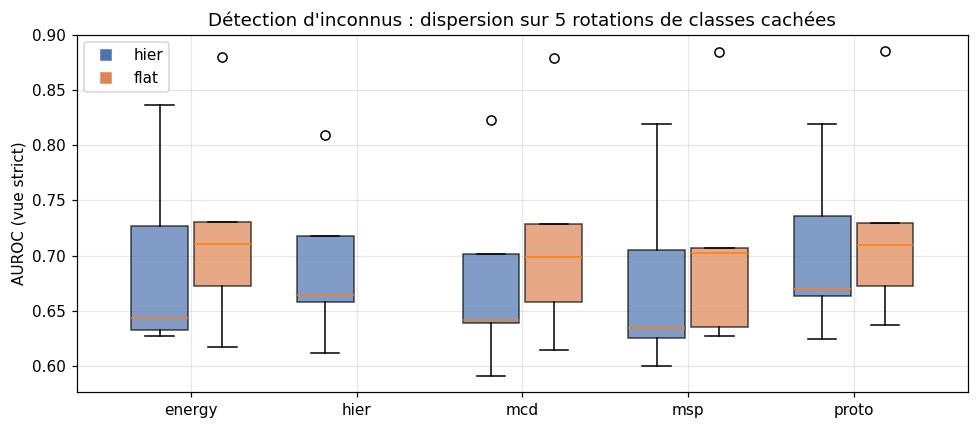

09:23:58 | INFO | Figure sauvegardée : /content/outputs/figs/F1_auroc_boxplot.png


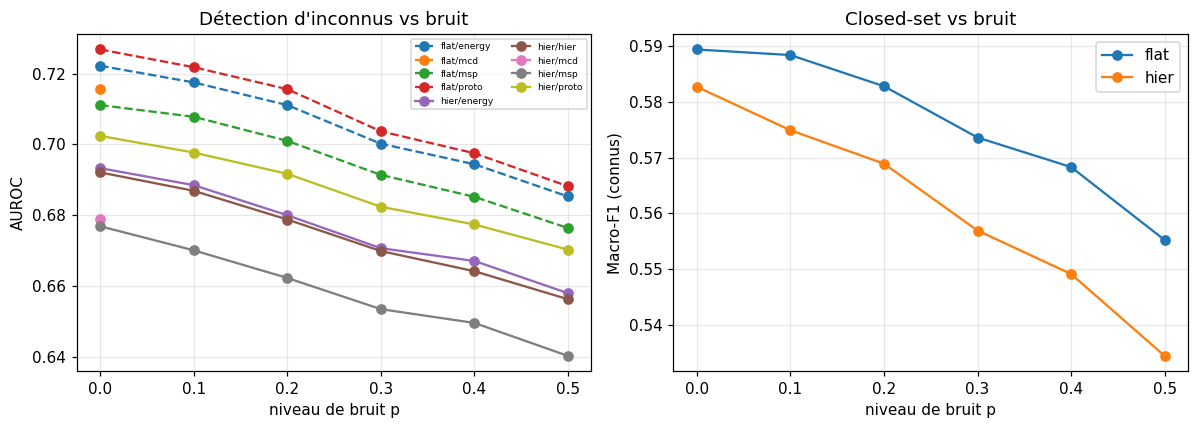

09:23:59 | INFO | Figure sauvegardée : /content/outputs/figs/F2_robustness_noise.png


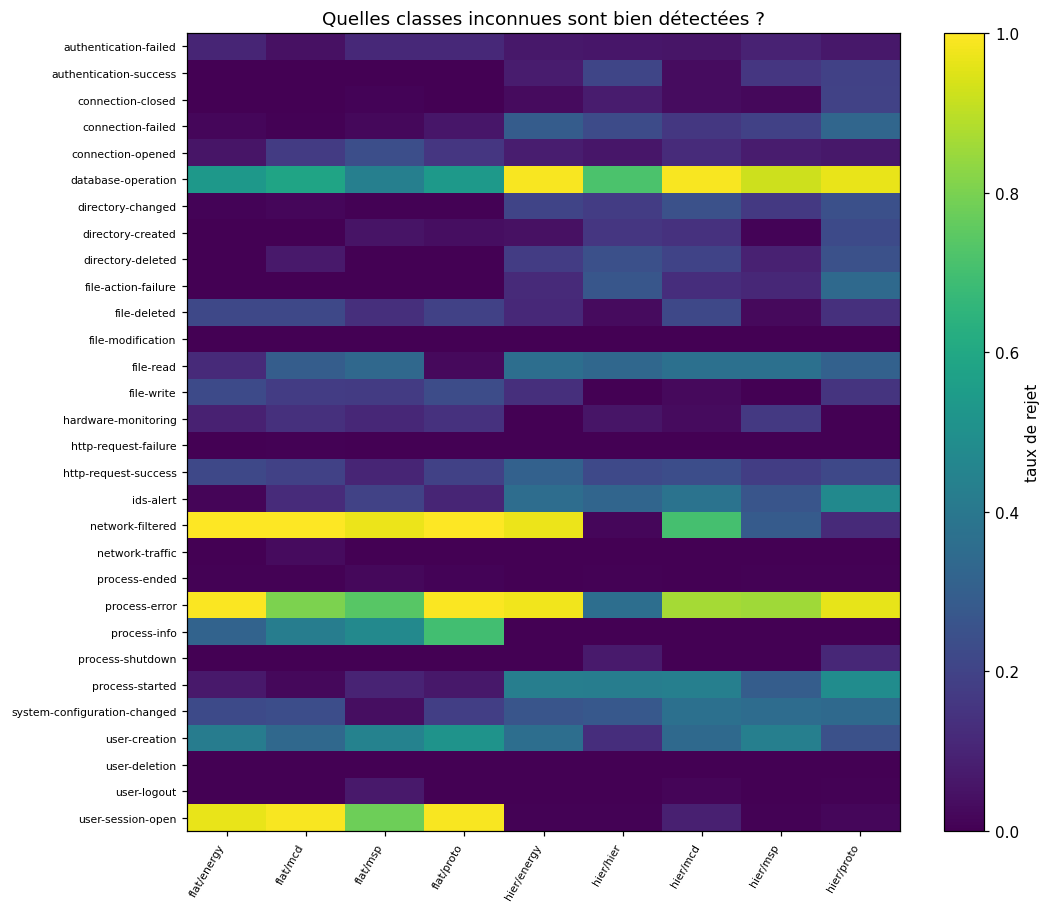

09:24:00 | INFO | Figure sauvegardée : /content/outputs/figs/F3_reject_per_class.png


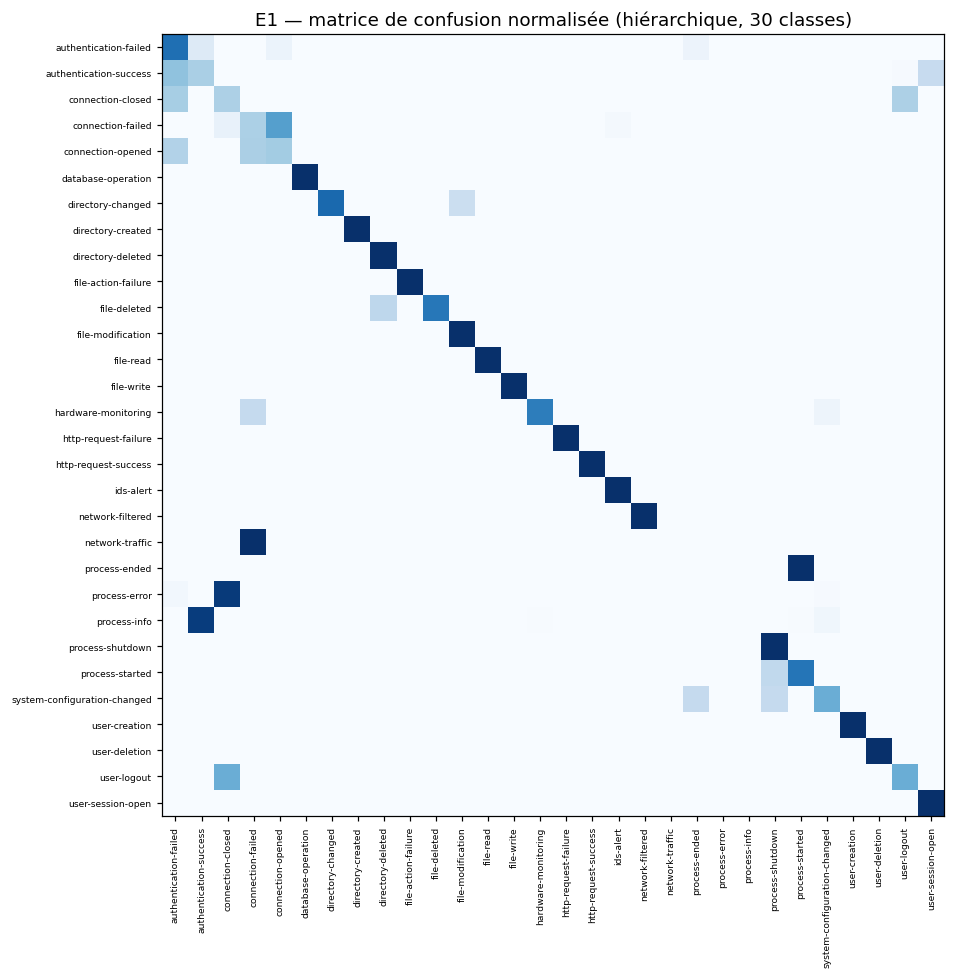

09:24:01 | INFO | Figure sauvegardée : /content/outputs/figs/F4_E1_confusion.png


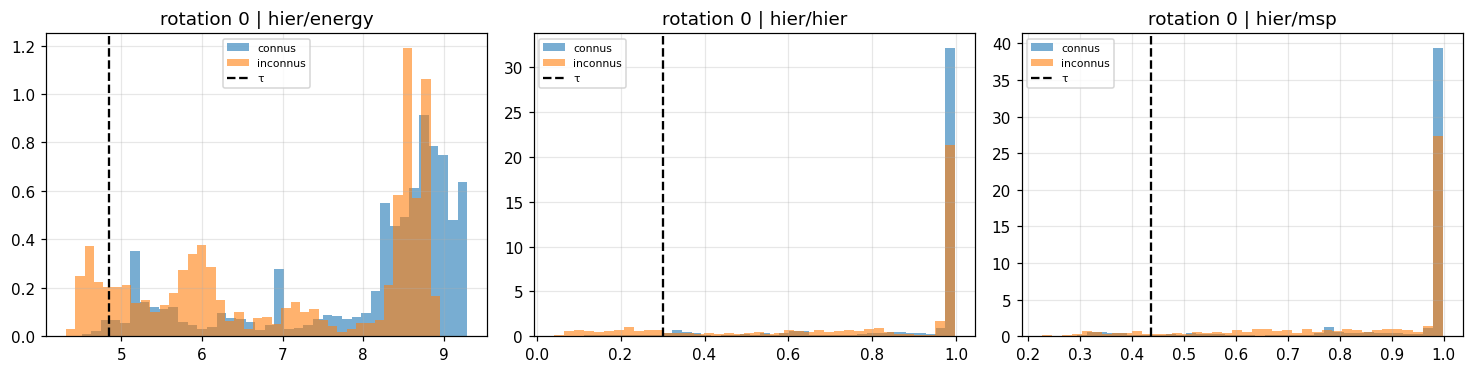

09:24:02 | INFO | Figure sauvegardée : /content/outputs/figs/F5_score_hist_rot0.png


In [14]:
section('12. FIGURES')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
def savefig(name):
    p = OUT_DIR / 'figs' / name; plt.tight_layout(); plt.savefig(p, bbox_inches='tight'); plt.show(); log.info('Figure sauvegardée : %s', p)

# F1 — AUROC par méthode, hier vs flat, réparti sur les rotations
d = clean_o[clean_o.view == 'strict']; methods = sorted(d.method.unique())
fig, ax = plt.subplots(figsize=(9, 4)); w = .38
for j, mod in enumerate(['hier', 'flat']):
    data = [d[(d.model == mod) & (d.method == m)].auroc.values for m in methods]
    pos = np.arange(len(methods)) + (j - .5) * w
    bp = ax.boxplot([x if len(x) else [np.nan] for x in data], positions=pos, widths=w * .9, patch_artist=True)
    for b in bp['boxes']: b.set_facecolor(['#4c72b0', '#dd8452'][j]); b.set_alpha(.7)
    ax.plot([], [], 's', color=['#4c72b0', '#dd8452'][j], label=mod)
ax.set_xticks(np.arange(len(methods))); ax.set_xticklabels(methods); ax.set_ylabel('AUROC (vue strict)'); ax.legend()
ax.set_title(f'Détection d\'inconnus : dispersion sur {CFG["n_rotations"]} rotations de classes cachées'); savefig('F1_auroc_boxplot.png')

# F2 — robustesse au bruit
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for (mod, me), g in T_ROB.reset_index().groupby(['model', 'method']):
    axs[0].plot(g.p, g.auroc, marker='o', ls='-' if mod == 'hier' else '--', label=f'{mod}/{me}')
axs[0].set_xlabel('niveau de bruit p'); axs[0].set_ylabel('AUROC'); axs[0].set_title('Détection d\'inconnus vs bruit'); axs[0].legend(fontsize=6, ncol=2)
for mod, g in T_ROBC.reset_index().groupby('model'): axs[1].plot(g.p, g.f1, marker='o', label=mod)
axs[1].set_xlabel('niveau de bruit p'); axs[1].set_ylabel('Macro-F1 (connus)'); axs[1].set_title('Closed-set vs bruit'); axs[1].legend()
savefig('F2_robustness_noise.png')

# F3 — heatmap rejet par classe inconnue
hm = T_CLS.drop(columns=['famille', 'stricte']); hm.columns = [f'{a}/{b}' for a, b in hm.columns]
fig, ax = plt.subplots(figsize=(10, max(4, .28 * len(hm)))); im = ax.imshow(hm.values.astype(float), aspect='auto', vmin=0, vmax=1, cmap='viridis')
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns, rotation=60, ha='right', fontsize=7); ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index, fontsize=7)
plt.colorbar(im, label='taux de rejet'); ax.set_title('Quelles classes inconnues sont bien détectées ?'); ax.grid(False); savefig('F3_reject_per_class.png')

# F4 — confusion E1
cmn = E1['cm']['hier'].astype(float); cmn /= cmn.sum(1, keepdims=True).clip(1)
fig, ax = plt.subplots(figsize=(10, 9)); ax.imshow(cmn, cmap='Blues'); ax.set_xticks(range(30)); ax.set_yticks(range(30))
ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=6); ax.set_yticklabels(CLASS_NAMES, fontsize=6); ax.grid(False)
ax.set_title('E1 — matrice de confusion normalisée (hiérarchique, 30 classes)'); savefig('F4_E1_confusion.png')

# F5 — histogrammes de scores (rotation 0)
keys = [(0, 'hier', m) for m in ['energy', 'hier', 'msp'] if (0, 'hier', m) in ALL['dump']]
if keys:
    fig, axs = plt.subplots(1, len(keys), figsize=(4.5 * len(keys), 3.5))
    for ax, k in zip(np.atleast_1d(axs), keys):
        sk, su, tau = ALL['dump'][k]
        ax.hist(sk, bins=40, alpha=.6, density=True, label='connus'); ax.hist(su, bins=40, alpha=.6, density=True, label='inconnus')
        ax.axvline(tau, color='k', ls='--', label='τ'); ax.set_title(f'rotation 0 | {k[1]}/{k[2]}'); ax.legend(fontsize=7)
    savefig('F5_score_hist_rot0.png')

In [15]:
section('13. RECAP FINAL')
def df_s(df): return df.to_string()
rec = []
rec.append('# RECAP — Open-World Hierarchical Classification (SIEVE)\n')
rec.append(f'Généré le {time.strftime("%Y-%m-%d %H:%M")} | QUICK={QUICK} | backbone={CFG["backbone"]} | rotations={CFG["n_rotations"]} (inconnues par rotation={CFG["n_unknown"]})\n')
rec.append('## Configuration\n```json\n' + json.dumps(CFG, indent=1) + '\n```\n')
rec.append('## Données\n```\n' + df_s(QC) + '\n```\n')
rec.append(f'Classes strictes (split par template, sans fuite) : {int(STRICT.sum())}/30. Non strictes (fuite résiduelle, split aléatoire) : {[CLASS_NAMES[c] for c in range(30) if not STRICT[c]]}\n')
rec.append('## Rotations des classes cachées\n```\n' + df_s(rt) + '\n```\n')
rec.append('## E1 — Closed-set (30 classes)\n```\n' + df_s(R_E1[R_E1.test_set == "clean"].set_index(["model", "view"]).round(4)) + '\n```\n')
rec.append('## E2 — Détection d\'inconnus (moyenne ± std sur rotations) — vue STRICT (sans fuite de template)\n```\n' + df_s(T_OOD['strict']) + '\n```\n')
rec.append('## E2 — idem vue ALL\n```\n' + df_s(T_OOD['all']) + '\n```\n')
rec.append('## E3 — Closed-set sur connus & qualité hiérarchique\n```\n' + df_s(T_CL) + '\n```\n')
rec.append('## Stabilité selon les classes cachées (AUROC strict)\n```\n' + df_s(T_CI) + '\n```\n')
rec.append('## Hiérarchique − Flat (apparié)\n```\n' + df_s(T_PAIR) + '\n```\n')
rec.append('## E4 — Robustesse au bruit\n```\n' + df_s(T_ROB) + '\n\n' + df_s(T_ROBC) + '\n```\n')
rec.append('## Rejet par classe inconnue\n```\n' + df_s(T_CLS) + '\n```\n')
rec.append('## Limites à discuter dans le papier\n'
           '- Données **synthétiques** (440 templates × Faker) : une fuite de template résiduelle existe pour les classes non strictes → privilégier la vue `strict`.\n'
           '- Les groupes sont **reconstruits** par clustering (k connu) : approximation des templates réels.\n'
           '- La **taxonomie est une construction** à valider par un expert SIEM.\n'
           '- Masquer des classes **simule** l\'open-set ; ne prouve pas la détection de toute nouveauté réelle.\n'
           '- Pas de test CDS réel (440 logs non fournis) : les versions bruitées mesurent la robustesse lexicale, pas le transfert réel.\n'
           '- Non couverts : OpenMax, ensembles profonds (seul MC-Dropout est testé).\n'
           f'- {CFG["n_rotations"]} rotations : IC95 larges, Wilcoxon p_min = 2/2^{CFG["n_rotations"]}.\n')
(OUT_DIR / 'RECAP.md').write_text('\n'.join(rec), encoding='utf-8')
log.info('RECAP.md écrit : %s', OUT_DIR / 'RECAP.md')

zp = OUT_DIR.parent / (OUT_DIR.name + '.zip')
with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in OUT_DIR.rglob('*'):
        if f.is_file() and 'ckpt' not in f.parts: z.write(f, f.relative_to(OUT_DIR.parent))
log.info('Archive : %s (%.1f Mo)', zp, zp.stat().st_size / 1e6)
log.info('FIN. Fichier à ouvrir en premier : %s', LOG_PATH)
try:
    from google.colab import files; files.download(str(zp))
except Exception: pass

09:24:02 | INFO | 
## 13. RECAP FINAL
09:24:02 | INFO | RECAP.md écrit : /content/outputs/RECAP.md
09:24:03 | INFO | Archive : /content/outputs.zip (0.4 Mo)
09:24:03 | INFO | FIN. Fichier à ouvrir en premier : /content/outputs/recap.log


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
